# Timestral: does a covariate-aware pretrained model help?

We test the 5M and 28M models from [Mistral's official Timestral repository](https://github.com/mistralai/timestral). Each runs locally on CPU with 504 hours (21 days) of history, using its native median as the point forecast.

Each size has two variants:
- **Target only:** past generation, no weather.
- **Weather:** past generation plus seven weather variables across the context and forecast horizon. Historical validation uses observed weather or the same illustrative stress scenarios as previous models. Actual future forecasts use `weather_forecast.csv`.

A fixed 50/50 blend combines the 28M weather model with the previous five-model equal-weight ensemble. No fine-tuning is performed. The 123M and 209M sizes are not tested in this run.

## Fair comparison
Six early blocks calibrate intervals; the same eleven selection blocks choose the lowest weather-stress pooled RMSE; the previously seen latest block remains a separate audit. The three weather scenarios are sensitivity assumptions, not measured forecast errors or independent windows. Previous forecasts are reused on identical dates.

Future target values never enter the model context or covariates. Past observed weather and future forecast weather are explicitly separated when preparing inputs. All inference runs locally with downloaded model weights.

Nominal 95% intervals are calibrated from historical forecast errors, separately for day one and day two. Native 5th/95th quantiles would be a 90% interval, not a 95% interval. Calibration is fixed during validation for Timestral, then refreshed for future forecasts. Earlier ensembles retain their own interval policies, so interval comparisons reflect calibration differences too.

More searches on reused validation windows introduce selection optimism. Broad benchmark claims do not guarantee success on this series, and pretraining overlap cannot be independently verified. No attempt is made to identify the original disguised series.

See `README.md` for reproduction commands and `results/timestral/model_versions.json` for pinned weight revisions.


In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd()/'scripts'))

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
out=Path("results/timestral")
report=json.loads((out/"run_summary.json").read_text())
summary=pd.read_csv(out/"model_comparison.csv")
windows=pd.read_csv(out/"window_comparison.csv",parse_dates=["start","end"])
consistency=pd.read_csv(out/"window_consistency.csv")
winner=report["selected_model"];best=report["best_timestral_candidate"]
focus=report["candidates"]+["seasonal_naive","SARIMA_21d","equal_mean","blend_SARIMA50_hour50"]
SCENARIO="weather_stress"  # or "observed_weather"
selection=summary[(summary.phase=="selection")&(summary.scenario==SCENARIO)&summary.model.isin(focus)]
print("Overall selected:",winner,"\nBest Timestral candidate:",best)
display(selection.set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))
print("Observed versus perturbed weather RMSE")
display(summary[(summary.phase=="selection")&summary.model.isin(focus)].pivot(index="model",columns="scenario",values="RMSE").round(2))


Overall selected: timestral_28m_weather_504h 
Best Timestral candidate: timestral_28m_weather_504h


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
timestral_28m_weather_504h,240.792,0.757,142.032,1199.518,0.903
blend_equal50_timestral28_weather50,243.131,0.764,244.501,1308.452,0.869
timestral_5m_weather_504h,263.988,0.830,181.575,1452.448,0.871
equal_mean,265.861,0.836,353.880,1188.786,0.946
blend_SARIMA50_hour50,277.105,0.871,355.026,1422.269,0.888
timestral_5m_target_504h,309.306,0.972,256.320,1690.353,0.860
timestral_28m_target_504h,313.924,0.987,289.719,1863.977,0.866
seasonal_naive,318.144,1.000,392.611,2258.119,0.771
SARIMA_21d,320.563,1.008,257.281,1466.273,0.928


Observed versus perturbed weather RMSE


scenario,observed_weather,weather_stress
model,,
SARIMA_21d,320.56,320.56
blend_SARIMA50_hour50,273.48,277.10
blend_equal50_timestral28_weather50,240.52,243.13
equal_mean,261.78,265.86
seasonal_naive,318.14,318.14
timestral_28m_target_504h,313.92,313.92
timestral_28m_weather_504h,241.91,240.79
timestral_5m_target_504h,309.31,309.31
timestral_5m_weather_504h,256.50,263.99


## Window wins and consistency
Below 1 beats seasonal naive. The final audit column is excluded from selection and win counts.

label,Oct 03,Oct 05,Oct 07,Oct 09,Oct 11,Oct 13,Oct 15,Oct 17,Oct 19,Oct 21,Oct 23,Oct 25 [audit]
model,,,,,,,,,,,,
timestral_28m_weather_504h,0.94,0.72,0.71,0.76,0.54,1.03,0.70,0.43,0.88,1.18,0.86,1.50
blend_equal50_timestral28_weather50,0.90,0.83,0.73,0.80,0.54,0.98,0.71,0.51,0.71,1.07,0.99,1.37
timestral_5m_weather_504h,1.10,0.83,0.97,0.55,0.65,0.97,0.64,0.38,0.96,1.37,1.13,2.42
equal_mean,0.91,0.99,0.76,0.88,0.60,1.05,0.75,0.66,0.72,1.00,1.20,1.43
blend_SARIMA50_hour50,0.89,1.02,0.92,1.08,0.58,0.99,0.75,0.65,0.70,1.00,1.14,1.35
timestral_5m_target_504h,0.78,1.22,0.75,0.95,0.96,1.21,0.83,0.39,0.91,1.48,2.21,1.14
timestral_28m_target_504h,0.81,1.22,0.78,0.89,0.82,0.99,0.81,0.39,0.86,1.58,2.69,1.39
seasonal_naive,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
SARIMA_21d,0.90,1.26,0.97,1.10,0.83,1.08,0.94,0.85,0.98,1.24,0.97,0.96


,windows,wins,mean_RMSE,median_RMSE_ratio,best_RMSE_ratio,worst_RMSE_ratio,mean_rank,win_rate,win_rate_pct
model,,,,,,,,,
blend_equal50_timestral28_weather50,11,10,237.513,0.800,0.505,1.072,7.091,0.909,90.909
timestral_28m_weather_504h,11,9,235.063,0.761,0.429,1.178,9.818,0.818,81.818
equal_mean,11,9,259.136,0.877,0.602,1.203,12.727,0.818,81.818
blend_SARIMA50_hour50,11,8,267.492,0.922,0.582,1.137,14.364,0.727,72.727
timestral_5m_weather_504h,11,8,253.945,0.955,0.382,1.370,14.818,0.727,72.727
timestral_28m_target_504h,11,8,299.538,0.858,0.391,2.691,20.545,0.727,72.727
timestral_5m_target_504h,11,7,299.707,0.946,0.390,2.213,24.000,0.636,63.636
SARIMA_21d,11,7,309.648,0.972,0.833,1.257,28.455,0.636,63.636
seasonal_naive,11,0,308.193,1.000,1.000,1.000,26.091,0.000,0.000


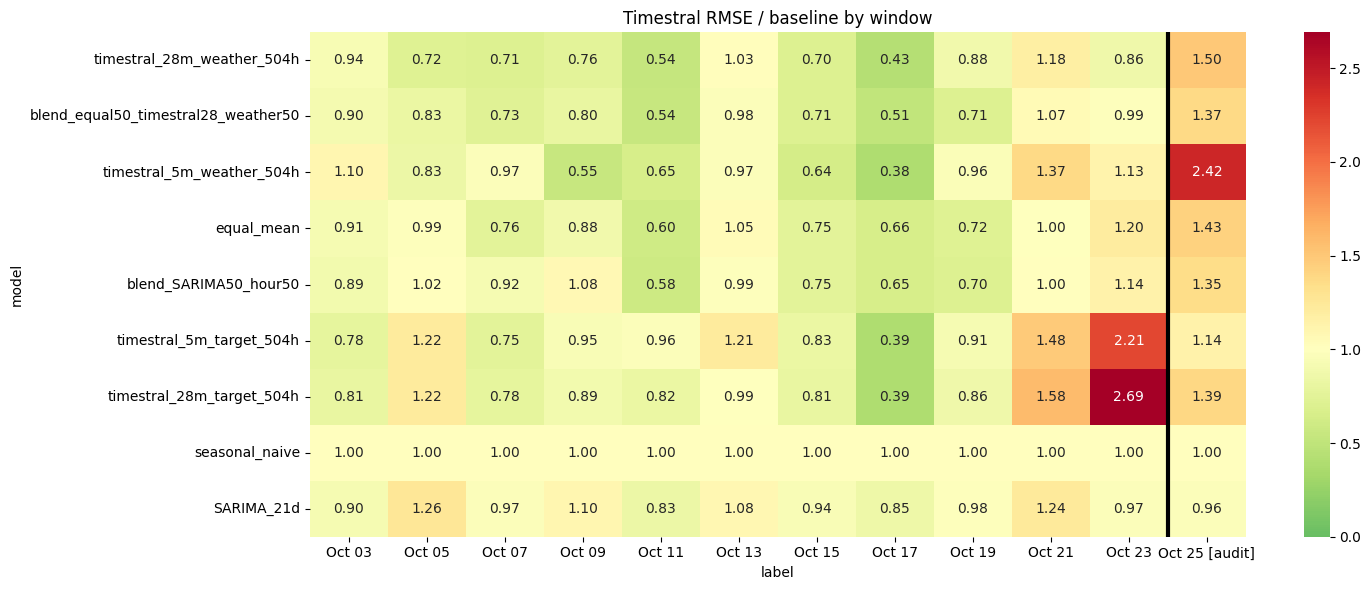

In [2]:
w=windows[(windows.scenario==SCENARIO)&windows.model.isin(focus)].copy()
w["label"]=w.start.dt.strftime("%b %d")+np.where(w.phase.eq("selection"),""," [audit]")
labels=w.sort_values("start").label.drop_duplicates().tolist()
ratios=w.pivot(index="model",columns="label",values="RMSE_ratio").reindex(index=selection.model,columns=labels)
display(ratios.round(2))
counts=consistency[(consistency.scenario==SCENARIO)&consistency.model.isin(focus)].set_index("model").drop(columns="scenario")
counts["win_rate_pct"]=100*counts.win_rate
display(counts.round(3))
fig,ax=plt.subplots(figsize=(15,6))
sns.heatmap(ratios,annot=True,fmt=".2f",cmap="RdYlGn_r",center=1,vmin=0,vmax=max(2,float(ratios.max().max())),ax=ax)
ax.axvline(11,color="black",lw=3);ax.set_title("Timestral RMSE / baseline by window")
plt.tight_layout();fig.savefig(out/"window_comparison.png",dpi=150,bbox_inches="tight");plt.show()


## Previously seen latest audit

In [3]:
audit=summary[(summary.phase=="last_window_audit")&(summary.scenario==SCENARIO)&summary.model.isin(focus)]
display(audit.set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
SARIMA_21d,116.108,0.964,38.789,904.063,1.000
seasonal_naive,120.404,1.000,51.088,568.464,1.000
timestral_5m_target_504h,137.334,1.141,39.008,711.482,1.000
blend_SARIMA50_hour50,162.473,1.349,50.306,716.054,0.993
blend_equal50_timestral28_weather50,164.562,1.367,58.169,763.861,0.965
timestral_28m_target_504h,167.209,1.389,55.388,712.416,0.979
equal_mean,172.215,1.430,60.560,808.858,1.000
timestral_28m_weather_504h,180.137,1.496,62.738,873.159,0.951
timestral_5m_weather_504h,290.995,2.417,65.047,2019.341,0.868


## Actual future forecast
The overall winner can remain a previous model. The best Timestral candidate is saved separately regardless of whether it wins overall.

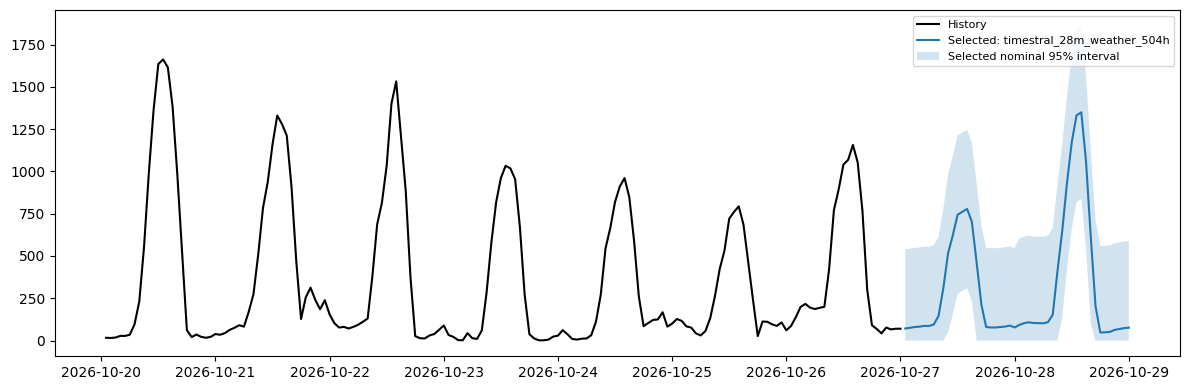

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,71.151276,0.0,539.670831
1,2026-10-27 02:00:00,75.421750,0.0,543.941309
2,2026-10-27 03:00:00,80.062530,0.0,548.582086
3,2026-10-27 04:00:00,82.007140,0.0,550.526697
4,2026-10-27 05:00:00,86.690430,0.0,555.209985


In [4]:
data=pd.read_csv("train.csv",parse_dates=["ds"])
sub=pd.read_csv(out/"selected_model_forecast.csv",parse_dates=["ds"])
ts=pd.read_csv(out/"best_timestral_forecast.csv",parse_dates=["ds"])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(data.ds.iloc[-168:],data.y.iloc[-168:],label="History",color="black")
ax.plot(sub.ds,sub.forecast,label=f"Selected: {winner}")
if winner!=best:ax.plot(ts.ds,ts.forecast,label=f"Best Timestral: {best}",linestyle="--")
ax.fill_between(sub.ds,sub.lower_95,sub.upper_95,alpha=.2,label="Selected nominal 95% interval")
ax.legend(fontsize=8);plt.tight_layout();fig.savefig(out/"forecast.png",dpi=150,bbox_inches="tight");plt.show()
display(sub.head())


## Save the selected forecast for Moodle
Set your surname. This creates a local CSV and does not upload it.

In [5]:
SURNAME=""
if SURNAME.strip():
    assert not any(c in SURNAME for c in "/\\")
    filename=f"{SURNAME.strip().upper()}_project.csv"
    pd.read_csv(out/"selected_model_forecast.csv").to_csv(filename,index=False)
    print("Saved",filename)
else:
    print("Set SURNAME to create the required Moodle filename.")


Set SURNAME to create the required Moodle filename.
